In [1]:
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

sys.path.insert(0, '.')
import analysis_utils as A

# the plot helpers always pass groups; plain KFold ignores them and warns
warnings.filterwarnings('ignore', message='The groups parameter is ignored')

## Helpers

### Data Loaders

**Choosing the nuisance set.** Set `NUIS_CHOICE` below (then re-run the notebook):

- `original`: the old list, with `log_med_err_frac` (and the dead `log_med_flux`, which is identically 0).
- `brightness_on`: noise floor as `log_noise_perp` plus brightness `log_F`. Same span as `original` for linear models, so it reproduces it; the result is age information **beyond** anything brightness-related (variability-specific).
- `brightness_off`: `log_noise_perp` only. Brightness is allowed to carry age information (all physical correlators, including any measurement effect that rides on brightness).
- `*_q` variants use `log_noise_q` = log(err_frac·√F) instead of the orthogonalised `log_noise_perp`; a robustness check.

Definitions and the reasoning are in `brightness_nuisances.tex`.


In [10]:
TABLE = '/astro/users/cgwill/TESS_Cluster_Age_ML/GenerateTable_CGW/data/cluster_table_Sep23_all_combos_le3sectors.pkl'
# Nuisance sets (see brightness_nuisances.tex).  log_med_err_frac ~ F^-1/2, so it mixes the
# noise floor with brightness, which in the LMC is itself an age correlator.  The
# reparameterised sets split it into brightness (log_F) and brightness-independent noise.
NUIS_BASE = ['log_cadence', 'n_sectors', 'log_n_points', 'cluster_radius', 'dec', 'gal_b']
NUIS_SETS = {
    'original':       NUIS_BASE + ['log_med_err_frac', 'log_med_flux'],  # log_med_flux is identically 0
    'brightness_on':  NUIS_BASE + ['log_noise_perp', 'log_F'],          # variability-specific
    'brightness_off': NUIS_BASE + ['log_noise_perp'],                   # all physical correlators
    'brightness_on_q':  NUIS_BASE + ['log_noise_q', 'log_F'],           # same, unorthogonalised noise term
    'brightness_off_q': NUIS_BASE + ['log_noise_q'],
}


NUIS_CHOICE = 'brightness_off'
NUIS = NUIS_SETS[NUIS_CHOICE]
NUIS_ALL = list(dict.fromkeys(n for s in NUIS_SETS.values() for n in s))   # every column per_cluster keeps
GALAXIES = ['MW', 'LMC', 'SMC']


def load_combos():
    # every sector combination (one row each) with log-transformed features,
    # plus position and radius from the ELK headers
    rows = A.load_rows(TABLE)
    rows = rows.merge(A.cluster_metadata(), on='name', how='left')
    rows = A.add_brightness_nuisances(rows)       # log_F, log_noise_q, log_noise_perp
    for col, tf, _ in A.feature_columns(rows):
        rows[col] = A.apply_transform(rows[col], tf)
    return rows[rows.age.notna()].reset_index(drop=True)


def disjoint_combos(rows, seed=0):
    # option B: for each cluster, take its longest combinations (3 sectors where it has them)
    # in random order and keep each one that shares no sector with those already kept
    rng = np.random.default_rng(seed)
    keep = []
    for name, d in rows.groupby('name'):
        d = d[d.n_sectors == d.n_sectors.max()]
        used = set()
        for i in rng.permutation(d.index):
            s = set(d.sectors[i])
            if not s & used:
                keep.append(i)
                used |= s
    return rows.loc[keep].reset_index(drop=True)


def per_cluster(rows):
    # one row per cluster: median of every feature and nuisance over that cluster's rows
    agg = {c: 'median' for c in FEAT + NUIS_ALL}
    agg.update(age='first', origin='first')
    return rows.groupby('name').agg(agg).reset_index()


def galaxy(df, g):
    # nuisances N, features F, log age y and cluster name (for grouped folds) for one galaxy,
    # missing values filled with that galaxy's median
    d = df[df.origin == g]
    N = d[NUIS].fillna(d[NUIS].median())
    F = d[FEAT].fillna(d[FEAT].median())
    return N, F, d.age, d.name

### Plotting

In [11]:

def rho_res(N, F, y):
    # Spearman rho of each feature with age, after regressing both on the nuisances (OLS)
    F_res = F - LinearRegression().fit(N, F).predict(N)
    y_res = y - LinearRegression().fit(N, y).predict(N)
    return F_res.corrwith(y_res, method='spearman')


def rho_raw(N, F, y):
    return F.corrwith(y, method='spearman')


def plot_corr(df, residualize=False, n_boot=1000):
    # (1)/(2) Spearman rho per feature, error bars = 95% range over bootstrap resamples of clusters
    rho_fn = rho_res if residualize else rho_raw
    fig, axs = plt.subplots(1, 3, figsize=(13, 7), sharex=True, sharey=True, layout='constrained')
    rng = np.random.default_rng(0)
    for ax, g in zip(axs, GALAXIES):
        N, F, y, _ = galaxy(df, g)
        rho = rho_fn(N, F, y)
        boot = pd.DataFrame([rho_fn(*(d.iloc[i].reset_index(drop=True) for d in (N, F, y)))
                             for i in rng.integers(0, len(y), (n_boot, len(y)))])
        lo, hi = boot.quantile(0.025), boot.quantile(0.975)
        ax.barh(rho.index, rho, xerr=[(rho - lo).clip(lower=0), (hi - rho).clip(lower=0)], capsize=2)
        ax.set(title=g, xlabel='Spearman rho with log age' + (' (residualized)' if residualize else ''))
    plt.show()


def plot_ridge(df, cv):
    # (3) ridge regression of log age, cross-validated R^2: nuisances only vs nuisances + features
    #     bars = mean over folds, error bars = std over folds, dots = individual folds
    fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True, layout='constrained')
    labels = ['nuisances', 'nuisances + features']
    x = np.arange(len(labels))
    rng = np.random.default_rng(0)
    for ax, g in zip(axs, GALAXIES):
        N, F, y, groups = galaxy(df, g)
        model = make_pipeline(StandardScaler(), RidgeCV(np.logspace(-2, 4, 30)))
        scores = [cross_val_score(model, X, y, cv=cv, groups=groups) for X in (N, N.join(F))]
        ax.bar(x, [s.mean() for s in scores], yerr=[s.std() for s in scores], capsize=4, alpha=0.6)
        for xi, s in zip(x, scores):
            ax.scatter(xi + rng.uniform(-0.12, 0.12, len(s)), s, color='k', s=15, zorder=3)
        ax.set_xticks(x, labels)
        ax.set(title=g, ylabel='cross-validated R$^2$')
    plt.show()


def plot_rf(df, cv):
    # (4) random forest, young/old split at each galaxy's median age, out-of-fold predictions
    #     top row: nuisances only, bottom row: nuisances + features
    fig, axs = plt.subplots(2, 3, figsize=(12, 8), layout='constrained')
    for j, g in enumerate(GALAXIES):
        N, F, y, groups = galaxy(df, g)
        old = y > y.median()
        for i, (name, X) in enumerate([('nuisances', N), ('nuisances + features', N.join(F))]):
            pred = cross_val_predict(RandomForestClassifier(random_state=0), X, old, cv=cv, groups=groups)
            ConfusionMatrixDisplay.from_predictions(old, pred, display_labels=['Young', 'Old'],
                                                    ax=axs[i, j], colorbar=False)
            axs[i, j].set_title(f'{g}: {name}')
    plt.show()

## Load every sector combination (all combinations of 1–3 sectors, per cadence)

In [12]:
rows = load_combos()
FEAT = [c for c, _, _ in A.feature_columns(rows)]

cv_clusters = KFold(5, shuffle=True, random_state=0)   # one row per cluster
cv_rows = GroupKFold(5)                                 # many rows per cluster: keep a cluster in one fold

17233 rows, 348 clusters from cluster_table_Sep23_all_combos_le3sectors.pkl
rows per cluster: median 3, max 409
log_noise_perp fit, d log err_frac / d log F (photon noise = -0.5): LMC -0.512, MW -0.524, SMC -0.496


# (A) Median over all sector combinations

In [13]:
df_A = per_cluster(rows)
df_A.groupby('origin').size()

origin
LMC    118
MW     124
SMC    106
dtype: int64

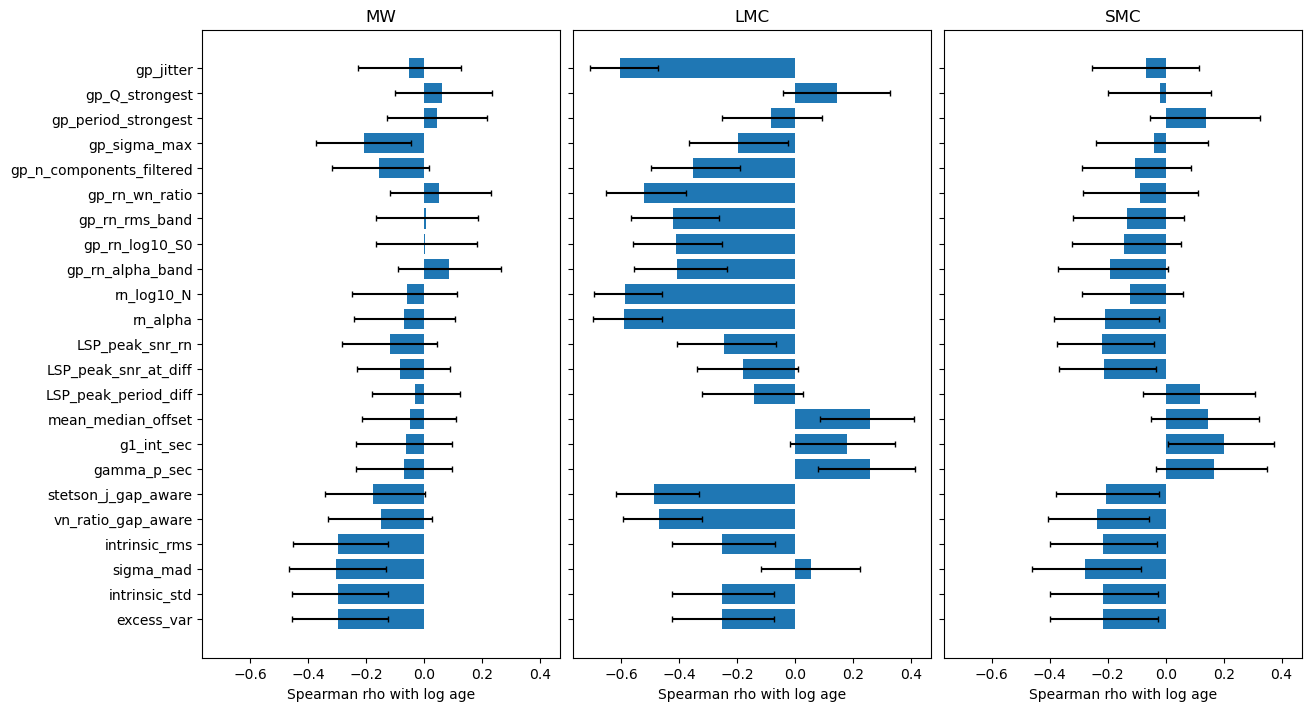

In [14]:
plot_corr(df_A)

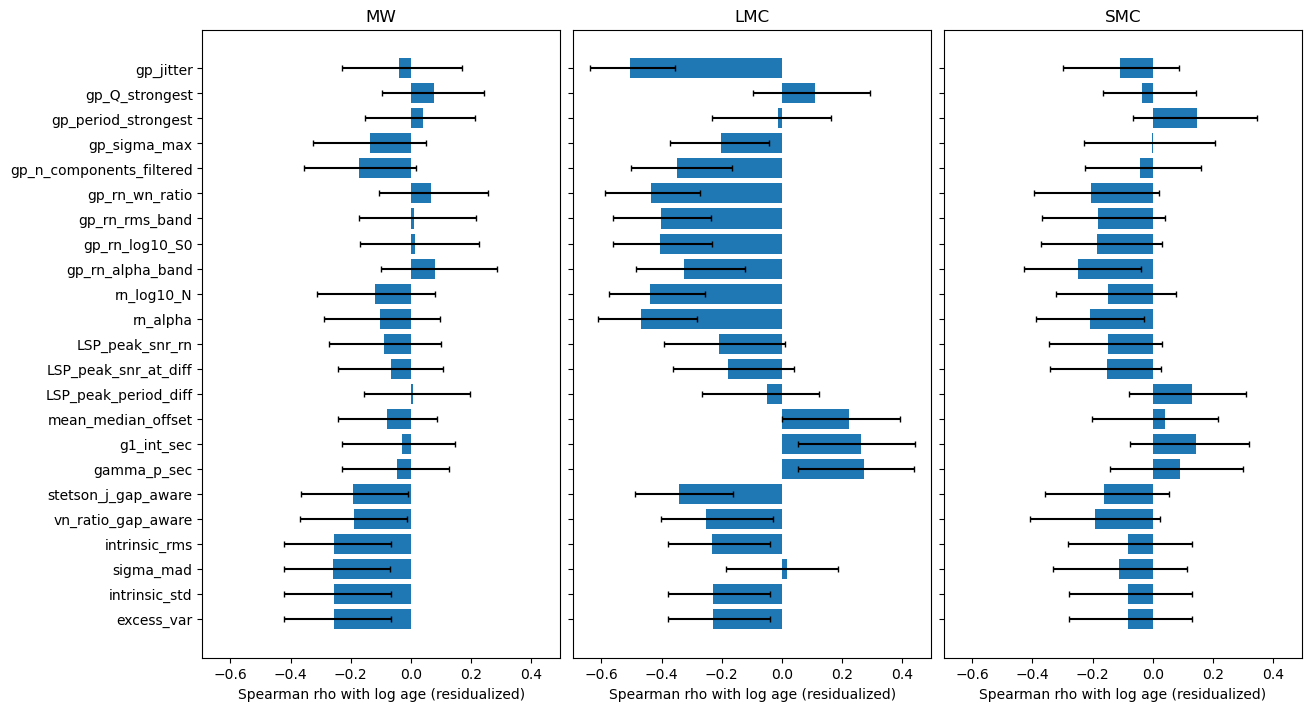

In [15]:
plot_corr(df_A, residualize=True)

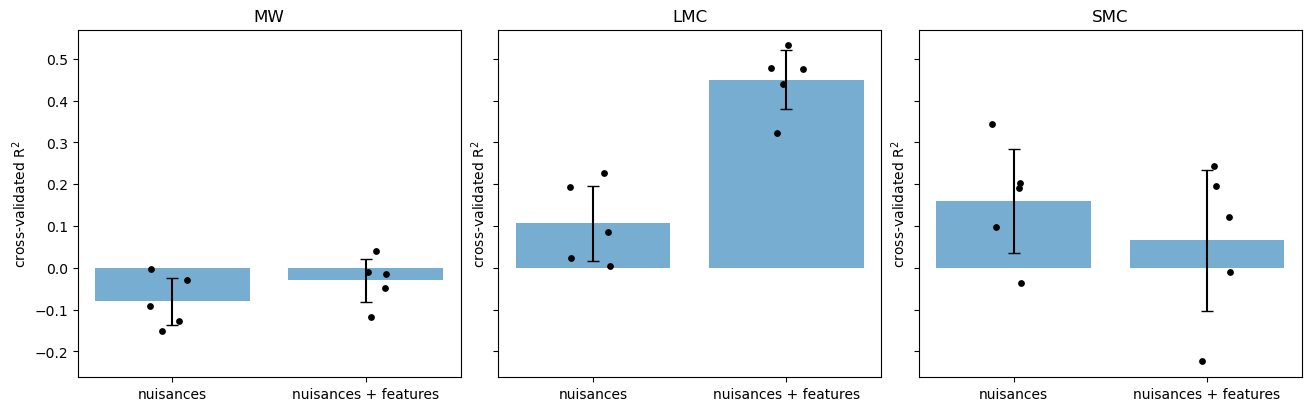

In [16]:
plot_ridge(df_A, cv_clusters)

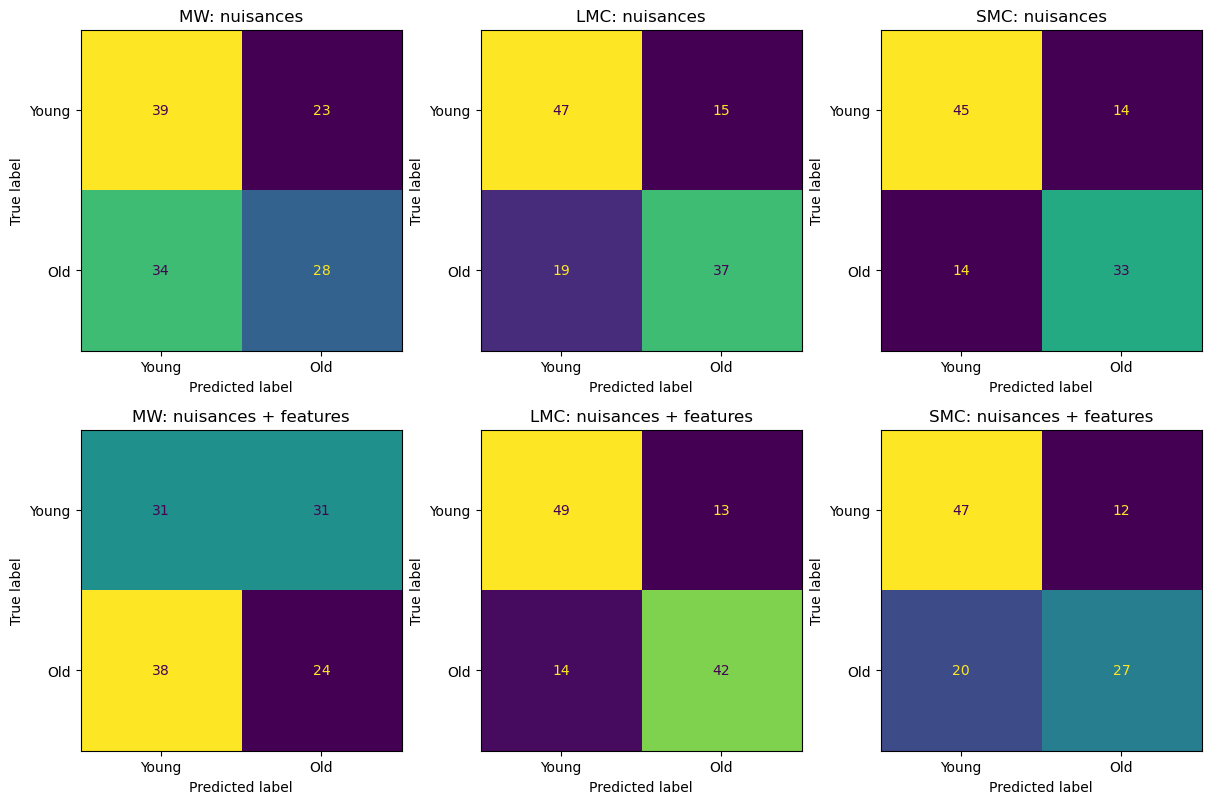

In [17]:
plot_rf(df_A, cv_clusters)

# (B) Non-overlapping 3-sector light curves, median per cluster

In [37]:
rows_B = disjoint_combos(rows)
df_B = per_cluster(rows_B)
print(rows_B.groupby('origin').n_sectors.value_counts().unstack())   # light curves of each length per galaxy
rows_B.groupby('name').size().groupby(df_B.set_index('name').origin).describe()   # light curves per cluster

n_sectors      1     2      3
origin                       
LMC          3.0   3.0  472.0
MW         122.0  50.0    8.0
SMC         69.0  43.0    NaN


,count,mean,std,min,25%,50%,75%,max
origin,,,,,,,,
LMC,118.0,4.050847,1.370304,1.0,3.0,4.0,5.0,7.0
MW,124.0,1.451613,0.515686,1.0,1.0,1.0,2.0,3.0
SMC,106.0,1.056604,0.232182,1.0,1.0,1.0,1.0,2.0


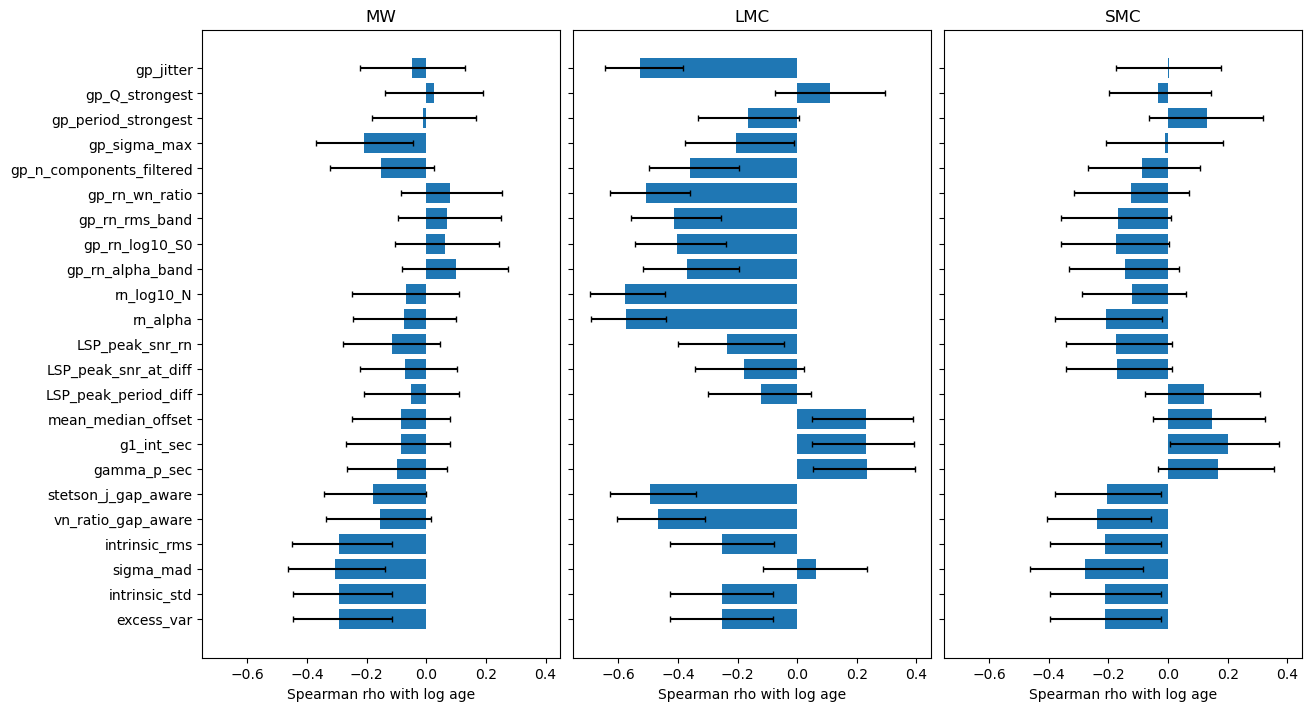

In [38]:
plot_corr(df_B)

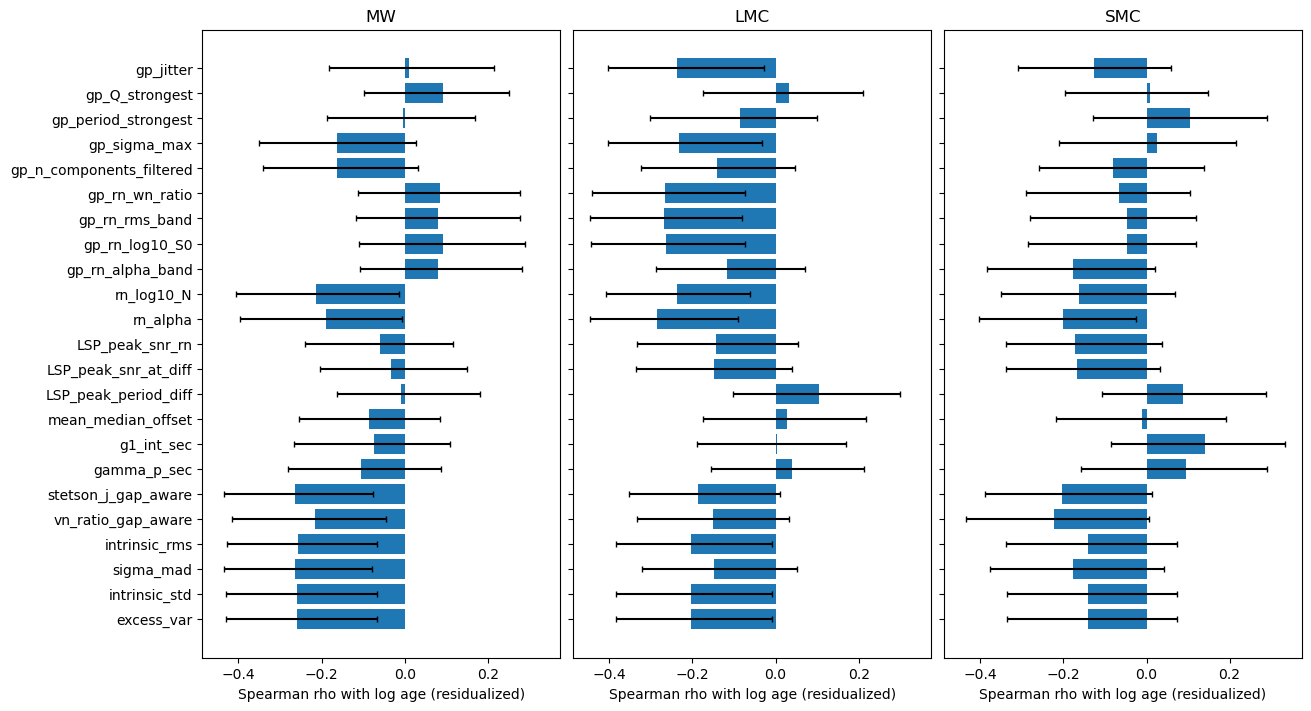

In [39]:
plot_corr(df_B, residualize=True)

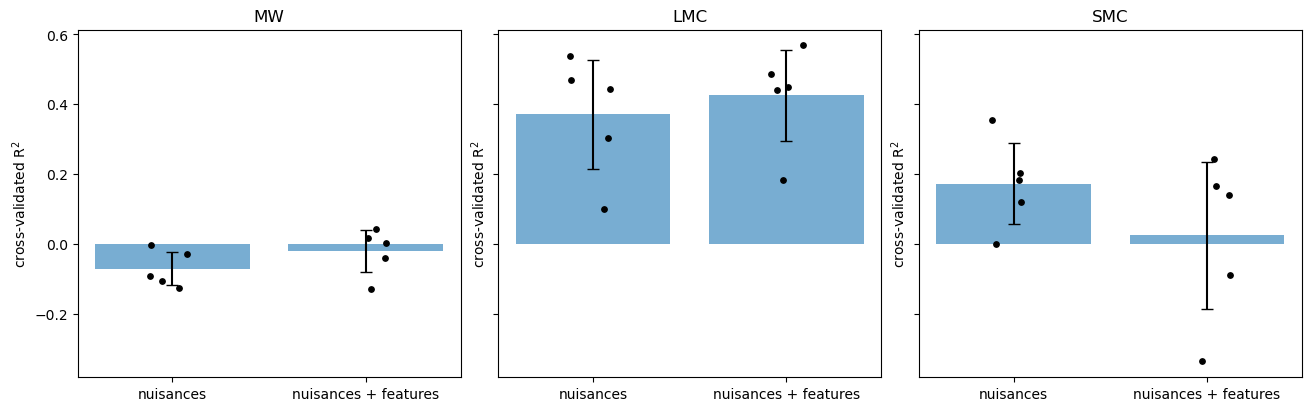

In [40]:
plot_ridge(df_B, cv_clusters)

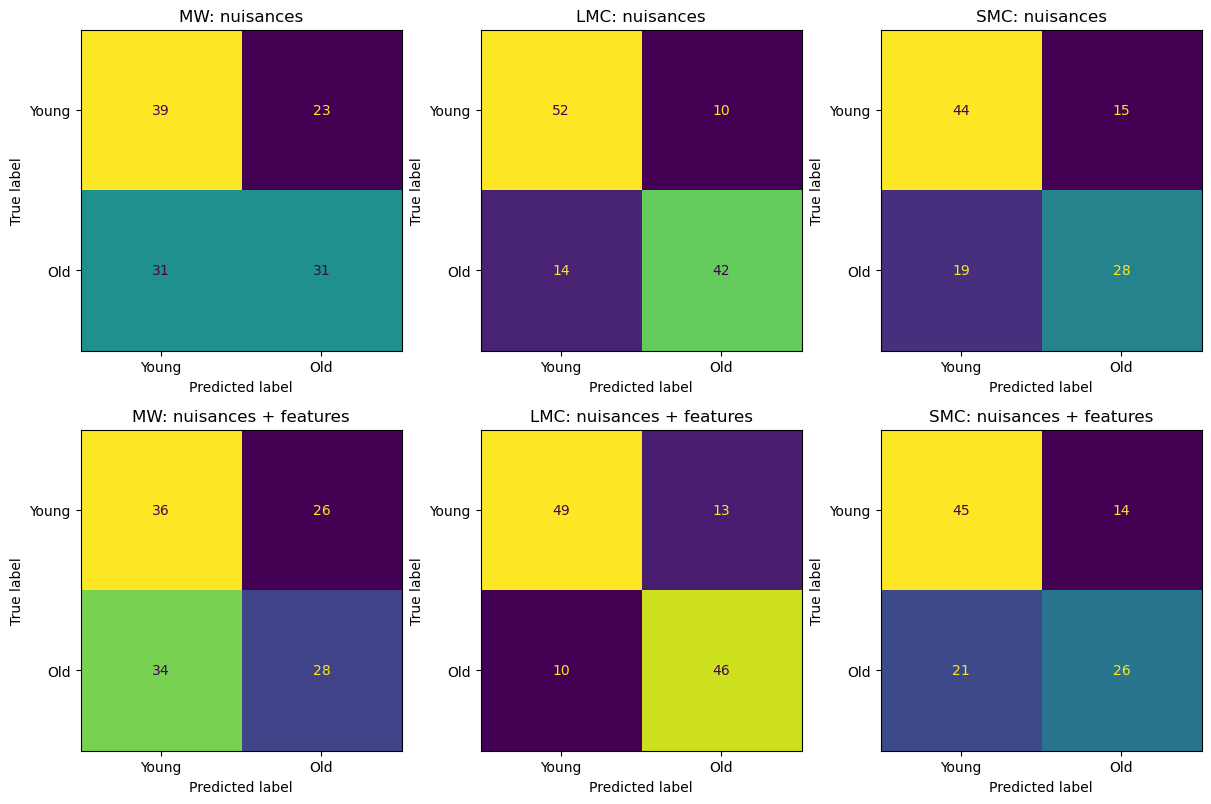

In [41]:
plot_rf(df_B, cv_clusters)

# One random 3-sector light curve per cluster

In [42]:
df_one = rows_B.groupby('name').sample(1, random_state=0).reset_index(drop=True)
df_one.groupby('origin').size()

origin
LMC    118
MW     124
SMC    106
dtype: int64

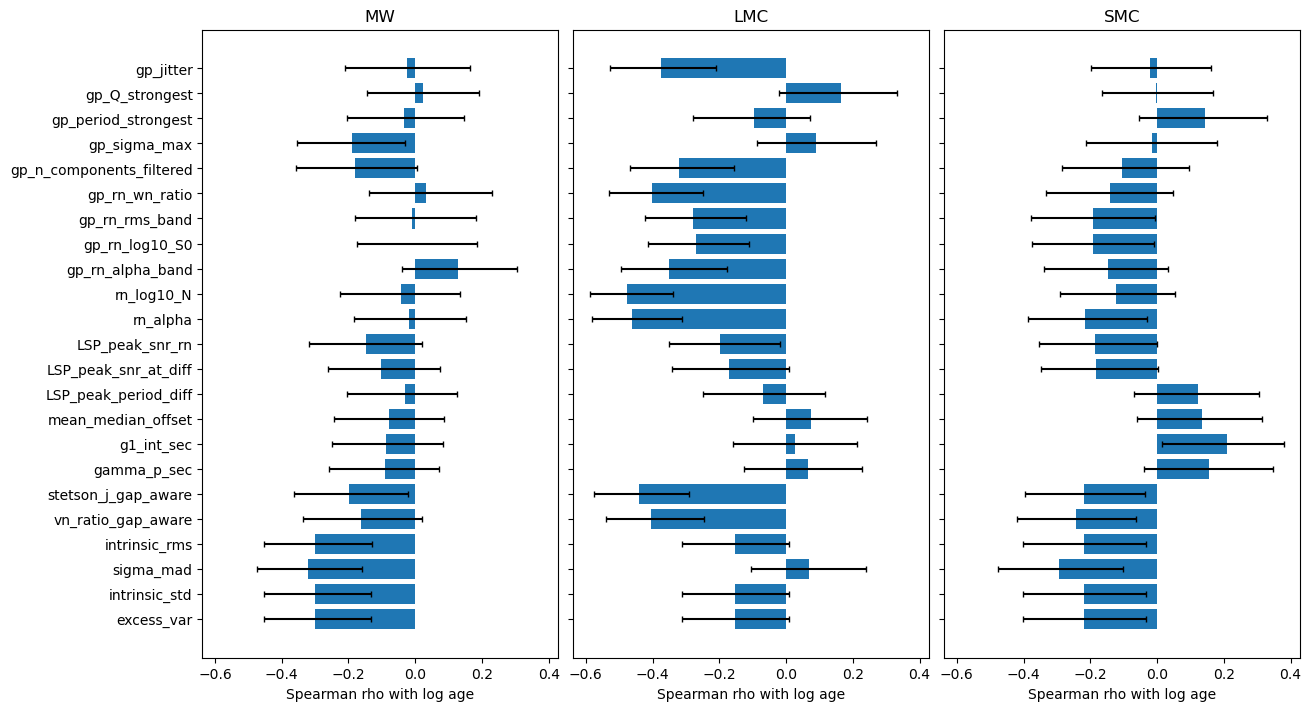

In [43]:
plot_corr(df_one)

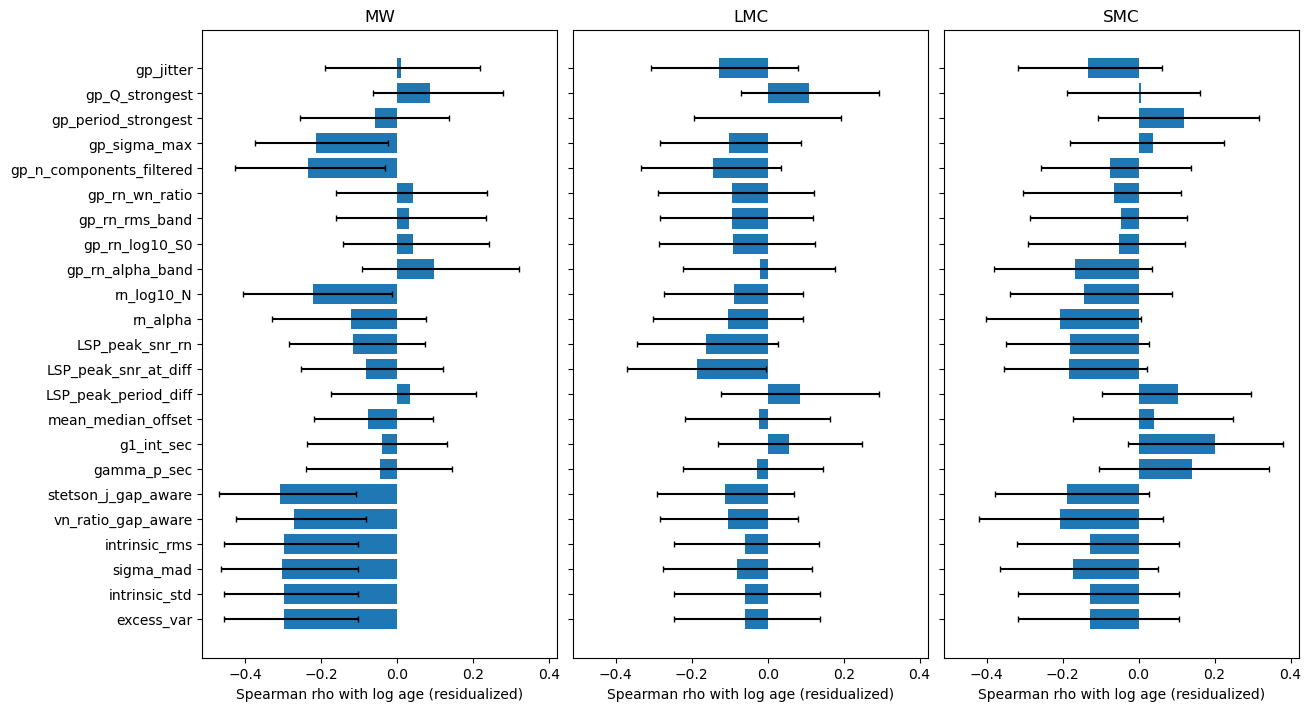

In [44]:
plot_corr(df_one, residualize=True)

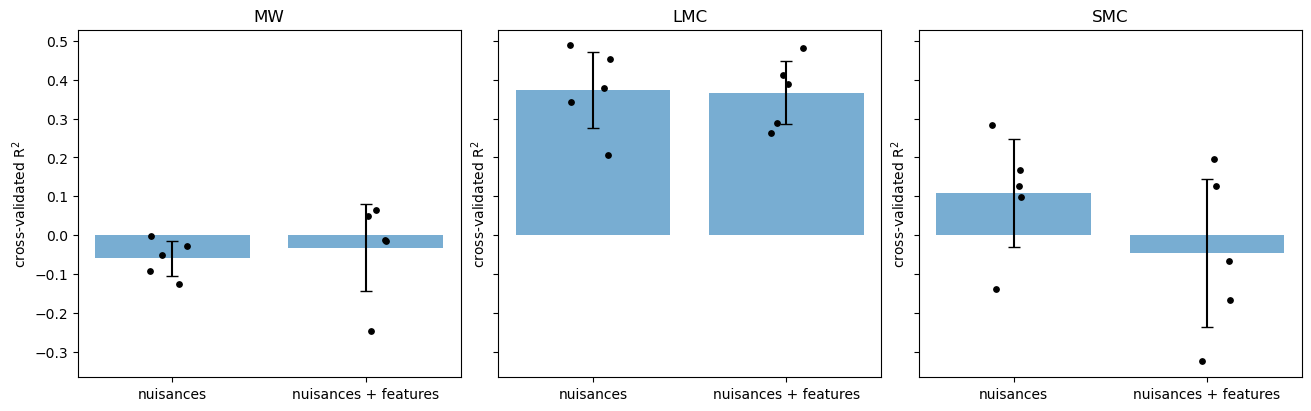

In [45]:
plot_ridge(df_one, cv_clusters)

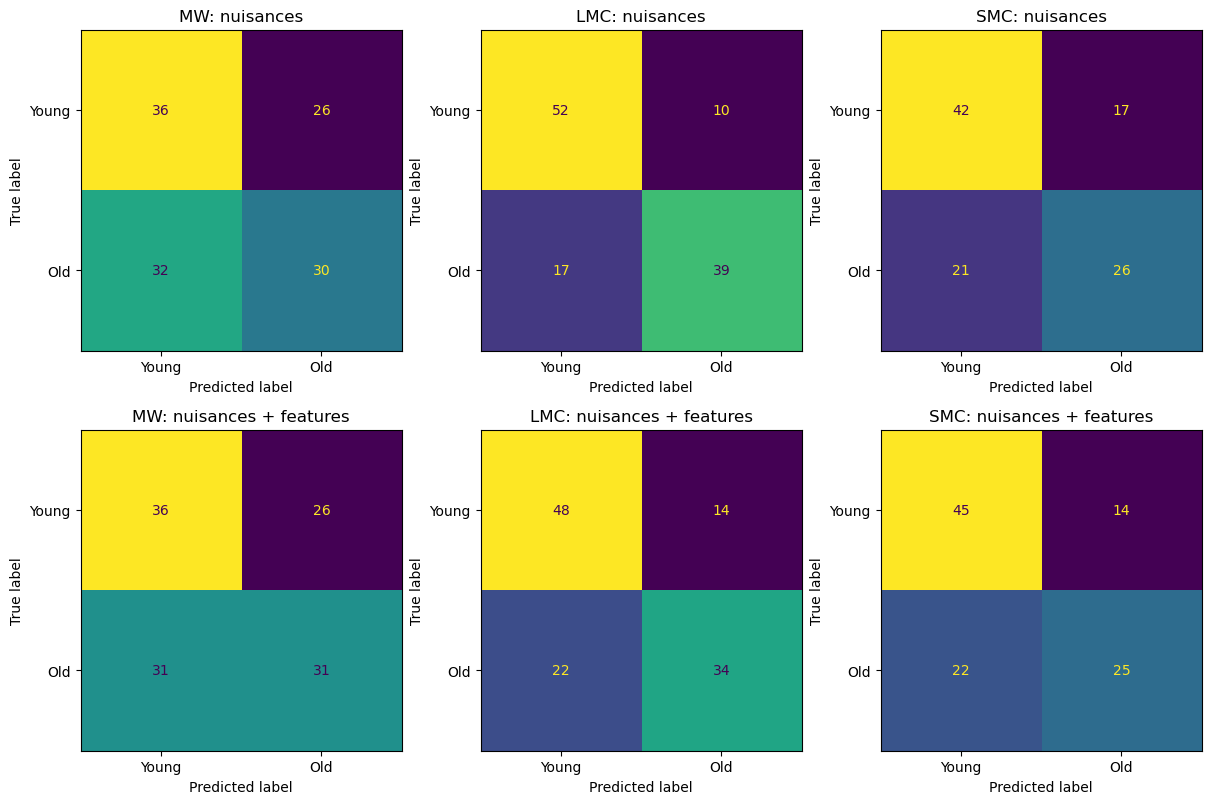

In [46]:
plot_rf(df_one, cv_clusters)

# All sector combinations as separate rows (folds grouped by cluster)

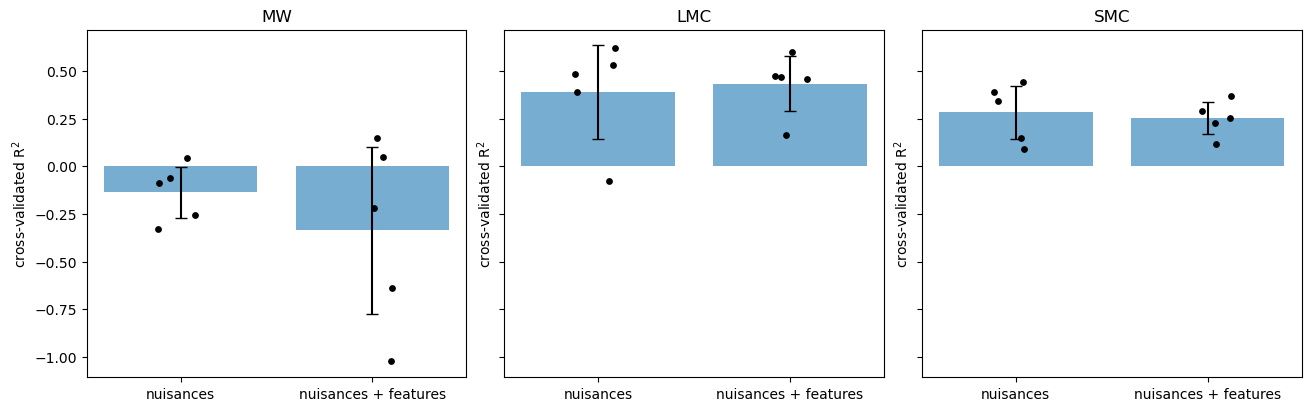

In [47]:
plot_ridge(rows, cv_rows)

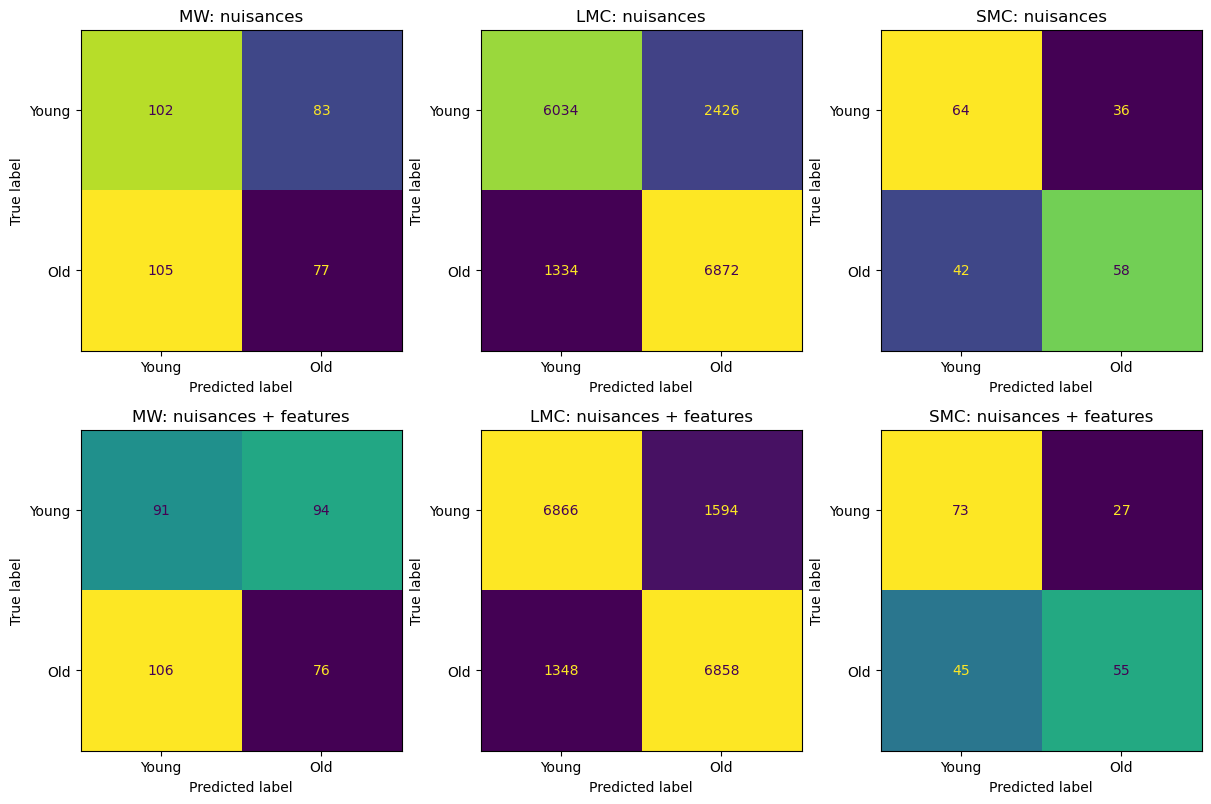

In [48]:
plot_rf(rows, cv_rows)